In [2]:
import os

print("Pasta atual:", os.getcwd())

arquivo = "yolov3.weights"

print("Arquivo encontrado:", os.path.exists(arquivo))

if os.path.exists(arquivo):
    print("Tamanho:", round(os.path.getsize(arquivo) / 1024**2, 2), "MB")

Pasta atual: C:\Users\jotav\Documents\FIAP\ANO1\FASE6\Assets - Cap 10
Arquivo encontrado: False


In [3]:
%cd ..

C:\Users\jotav\Documents\FIAP\ANO1\FASE6


In [4]:
import os
print(os.getcwd())

C:\Users\jotav\Documents\FIAP\ANO1\FASE6


In [5]:
%pip install opencv-python

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\jotav\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [6]:
import cv2

print("OpenCV:", cv2.__version__)

net = cv2.dnn.readNetFromDarknet(
    "darknet/cfg/yolov3.cfg",
    "darknet/yolov3.weights"
)

print("YOLOv3 carregado com sucesso!")

OpenCV: 5.0.0


AttributeError: module 'cv2.dnn' has no attribute 'readNetFromDarknet'

In [7]:
%pip uninstall -y opencv-python

Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Note: you may need to restart the kernel to use updated packages.


You can safely remove it manually.


In [8]:
%pip install opencv-python==4.13.0.92

   ---------------------------------------- 0.0/40.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/40.2 MB ? eta -:--:--
   - -------------------------------------- 1.3/40.2 MB 5.2 MB/s eta 0:00:08
   -- ------------------------------------- 2.6/40.2 MB 5.7 MB/s eta 0:00:07
   ---- ----------------------------------- 4.5/40.2 MB 6.5 MB/s eta 0:00:06
   ------ --------------------------------- 6.6/40.2 MB 7.4 MB/s eta 0:00:05
   --------- ------------------------------ 9.2/40.2 MB 8.5 MB/s eta 0:00:04
   ------------ --------------------------- 12.8/40.2 MB 9.9 MB/s eta 0:00:03
   ---------------- ----------------------- 17.0/40.2 MB 11.3 MB/s eta 0:00:03
   --------------------- ------------------ 22.0/40.2 MB 12.6 MB/s eta 0:00:02
   --------------------------- ------------ 27.5/40.2 MB 14.0 MB/s eta 0:00:01
   --------------------------------- ------ 33.6/40.2 MB 15.5 MB/s eta 0:00:01
   ---------------------------------------  39.3/40.2 MB 16.6 MB/s eta 0:00:01
  


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\jotav\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [1]:
import cv2

print("OpenCV:", cv2.__version__)

net = cv2.dnn.readNetFromDarknet(
    "darknet/cfg/yolov3.cfg",
    "darknet/yolov3.weights"
)

print("YOLOv3 carregado com sucesso!")

OpenCV: 4.13.0
YOLOv3 carregado com sucesso!


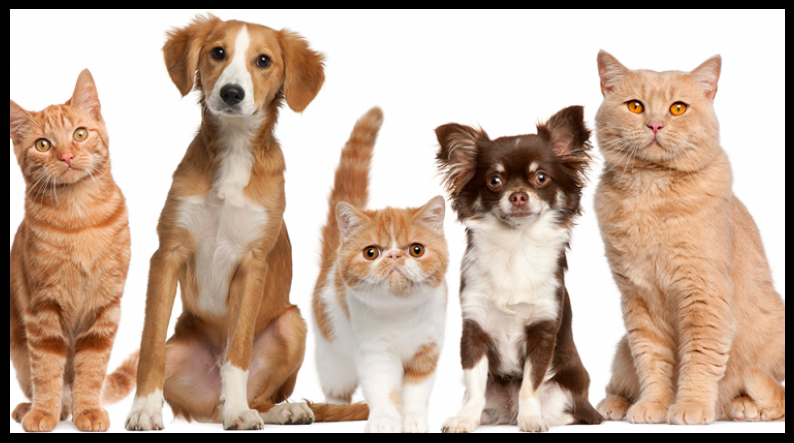

In [2]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread("pets.png")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 7))
plt.imshow(img_rgb)
plt.axis("off")
plt.show()

In [3]:
blob = cv2.dnn.blobFromImage(
    img,
    1/255.0,
    (416, 416),
    swapRB=True,
    crop=False
)

net.setInput(blob)

nomes_camadas = net.getLayerNames()
camadas_saida = [
    nomes_camadas[i - 1]
    for i in net.getUnconnectedOutLayers().flatten()
]

outputs = net.forward(camadas_saida)

print("YOLO executado!")
print("Camadas de saída:", len(outputs))

YOLO executado!
Camadas de saída: 3


cat: 99.12%
cat: 98.58%
dog: 97.23%
dog: 93.61%
cat: 84.23%


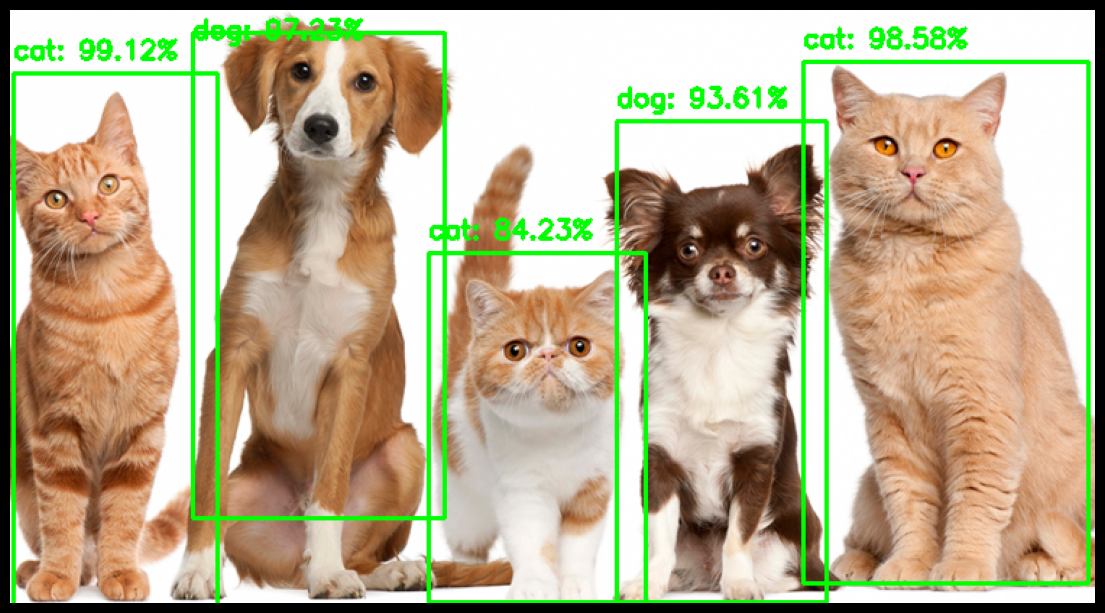

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Carregar nomes das classes COCO
with open("darknet/data/coco.names", "r") as f:
    classes = [linha.strip() for linha in f.readlines()]

altura, largura = img.shape[:2]

boxes = []
confidences = []
class_ids = []

# Processar resultados do YOLO
for output in outputs:
    for detection in output:
        scores = detection[5:]
        class_id = np.argmax(scores)
        confidence = scores[class_id]

        if confidence > 0.5:
            centro_x = int(detection[0] * largura)
            centro_y = int(detection[1] * altura)
            w = int(detection[2] * largura)
            h = int(detection[3] * altura)

            x = int(centro_x - w / 2)
            y = int(centro_y - h / 2)

            boxes.append([x, y, w, h])
            confidences.append(float(confidence))
            class_ids.append(class_id)

# Remover caixas duplicadas
indices = cv2.dnn.NMSBoxes(
    boxes,
    confidences,
    score_threshold=0.5,
    nms_threshold=0.4
)

resultado = img.copy()

for i in indices:
    i = int(i)

    x, y, w, h = boxes[i]
    classe = classes[class_ids[i]]
    confianca = confidences[i]

    cv2.rectangle(
        resultado,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

    texto = f"{classe}: {confianca:.2%}"

    cv2.putText(
        resultado,
        texto,
        (x, max(y - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (0, 255, 0),
        2
    )

    print(f"{classe}: {confianca:.2%}")

# Mostrar resultado
resultado_rgb = cv2.cvtColor(resultado, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(14, 8))
plt.imshow(resultado_rgb)
plt.axis("off")
plt.show()